# MuTech Phase 4: Detailed Topic Modeling Analysis
K-Means, Agglomerative, NMF, LDA. MuTech SLR on Intelligent Music Processing (MIR)

Companion to the quick-pipeline scripts (`kmeans_clustering.py`, `topic_models.py`), which
pick one k and stop there. Those are still the fast path for a sanity check. This notebook
is where the four models actually get validated: a real train/test split, hyperparameter
search, error analysis on the papers each model struggles with, and only then a final refit
on the whole corpus for the labels Phase 5 uses.

## Layout
1. Part 1 - EDA on the 365-paper corpus.
2. Data prep - 80/20 split, vectorizers refit on train only. Phase 3's `tfidf_vectorizer.pkl`
   was fit on all 365 papers, so it doesn't get touched anywhere in this notebook.
3. Part 2 - one section per model, same nine steps each: baseline fit, train/test check,
   baseline evaluation, cluster profile, error analysis, tuning, error-guided retuning,
   interpretation, final refit on the full corpus. That last model in each section is the
   one that actually produces the topic labels - not the train-split version.
4. Part 3 - cross-model comparison and a final pick.

### A note on "no leakage" without labels
Unsupervised clustering has no target to leak, but two things still need enforcing: a
vectorizer's vocabulary can't be shaped by documents that are supposed to be held out, and
hyperparameters can't get scored on the same data used to report how well the model
generalizes. So every vectorizer during validation is fit on the train split only and just
`.transform()`s test; tuning runs cross-validation inside train with the vectorizer refit
per fold through `Pipeline`; and test only gets touched once per model, for the actual
generalization check.

In [1]:
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")

import os
import pickle
import random as pyrandom

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import loguniform, randint as sp_randint

from sklearn.model_selection import train_test_split, RandomizedSearchCV, KFold
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import NMF, LatentDirichletAllocation, TruncatedSVD
from sklearn.metrics import (silhouette_score, silhouette_samples,
                              adjusted_rand_score, pairwise_distances)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pyrandom.seed(RANDOM_STATE)

TFIDF_PARAMS = dict(max_features=2000, min_df=2, max_df=0.90, ngram_range=(1, 2), sublinear_tf=True)
COUNT_PARAMS = dict(max_features=2000, min_df=2, max_df=0.90, ngram_range=(1, 2))
TOP_TERMS = 15

INDIR = os.path.join("..", "phase3", "phase3_output_real")
OUTDIR = "phase4_output_detailed"
os.makedirs(OUTDIR, exist_ok=True)
for sub in ("eda", "kmeans", "agglomerative", "nmf", "lda", "comparison"):
    os.makedirs(os.path.join(OUTDIR, sub), exist_ok=True)

print("Setup complete.")

Setup complete.


# Part 1: Exploratory Data Analysis

In [2]:
corpus_path = os.path.join(INDIR, "cleaned_corpus.csv")
assert os.path.exists(corpus_path), (
    f"[ERROR] {corpus_path} not found. Run phase3/text_mining.py on the real dataset first."
)
corpus = pd.read_csv(corpus_path)
required_cols = {"title", "abstract", "keywords", "year", "authors", "doi", "source", "tokens"}
missing_cols = required_cols - set(corpus.columns)
assert not missing_cols, f"[ERROR] cleaned_corpus.csv is missing columns: {missing_cols}"
assert len(corpus) == 365, f"[WARN] expected 365 papers (the agreed final corpus size), got {len(corpus)}"
print(f"Loaded {len(corpus)} papers from {corpus_path}")
corpus.head(3)

Loaded 365 papers from ..\phase3\phase3_output_real\cleaned_corpus.csv


,title,abstract,keywords,year,authors,doi,source,document_raw,document_clean,relevance_score,keep,drop_reason,tokens
0,Deep learning-based personalized learning path...,Music education is an art that emphasizes the ...,ALS-EDNN-ATT | Music education | Path recommen...,2026,Li J.,10.1007/s44163-026-01115-4,NaN,Deep learning-based personalized learning path...,deep learning based personalized learning path...,5,True,NaN,deep learning personalized learn path planning...
1,The multi-dimensional performance intelligent ...,This study seeks to address persistent challen...,Dimensionality reduction | Feedback system | I...,2026,Li M.,10.1007/s44163-026-01122-5,NaN,The multi-dimensional performance intelligent ...,the multi dimensional performance intelligent ...,5,True,NaN,multi dimensional performance intelligent eval...
2,Simulation-based deep learning for IoT-oriente...,Real-time music improvisation demands continuo...,Attention mechanism | Audio effects | Chaotic ...,2026,Liu M.,10.1007/s44163-026-01064-y,NaN,Simulation-based deep learning for IoT-oriente...,simulation based deep learning for iot oriente...,7,True,NaN,simulation deep learning orient music improvis...


### Initial Data Assessment

In [3]:
print("Dataset shape:", corpus.shape)
print()
print("Missing values per column:")
print(corpus.isna().sum())

Dataset shape: (365, 13)

Missing values per column:
title                0
abstract             0
keywords            19
year                 0
authors              0
doi                  0
source             365
document_raw         0
document_clean       0
relevance_score      0
keep                 0
drop_reason        365
tokens               0
dtype: int64


In [4]:
dup_doi = corpus["doi"].dropna().duplicated().sum()
print(f"Duplicate DOIs: {dup_doi} (dedup is Phase 2's job, this should be 0)")
print(f"Rows with keep == True: {(corpus['keep'] == True).sum()} / {len(corpus)}")
corpus["token_count"] = corpus["tokens"].fillna("").astype(str).str.split().str.len()
print(f"Papers with < 5 tokens after cleaning: {(corpus['token_count'] < 5).sum()}")

n_source = corpus["source"].notna().sum()
print(f"Papers with a non-empty source/venue: {n_source} / {len(corpus)}")

Duplicate DOIs: 0 (dedup is Phase 2's job, this should be 0)
Rows with keep == True: 365 / 365
Papers with < 5 tokens after cleaning: 0
Papers with a non-empty source/venue: 0 / 365


`source` comes back 0/365 populated, not just partially missing. Traced it back through
the pipeline rather than assuming it's just messy data: the Scopus extraction cell in the
Phase 1-2 notebook sets a which-database flag (`df_scopus['Source'] = 'Scopus'`) that a
later harmonization step mistakenly copied into `Publication Venue` as if it were the real
journal name - so ~90% of records never had a real venue to begin with. The IEEE records
did have one, but it didn't survive the Rayyan export/re-import round trip (`Publication
Venue` and Rayyan's own `journal` field are both empty for all 365 final records). Both
bugs are noted where they live; neither is recoverable without re-pulling from Scopus, so
venue-based analysis is dropped for the rest of this notebook and everything below uses
`year` instead, which is fully populated.

### Distribution Overview

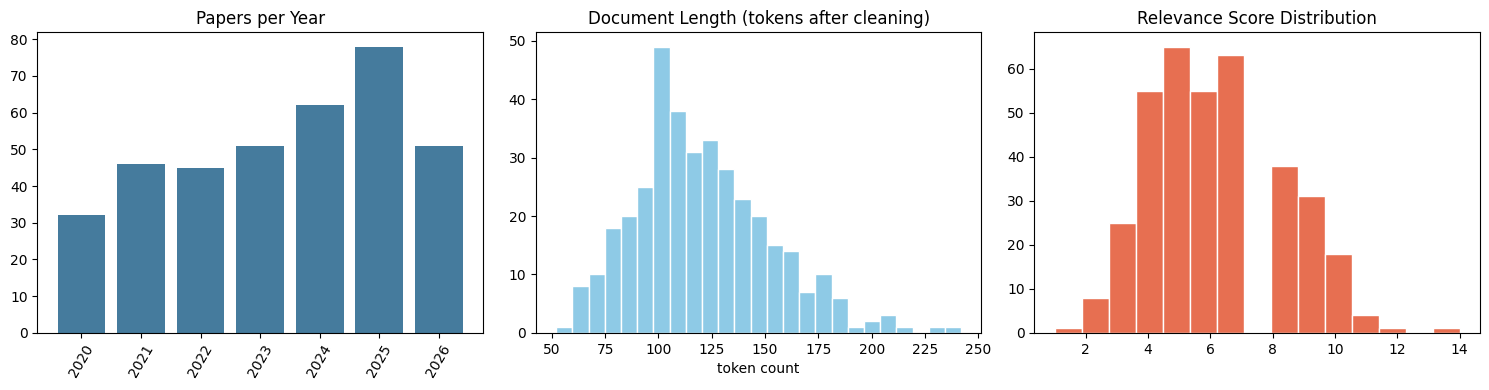

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

year_counts = corpus["year"].value_counts().sort_index()
axes[0].bar(year_counts.index.astype(str), year_counts.values, color="#457b9d")
axes[0].set_title("Papers per Year")
axes[0].tick_params(axis="x", rotation=60)

axes[1].hist(corpus["token_count"], bins=25, color="#8ecae6", edgecolor="white")
axes[1].set_title("Document Length (tokens after cleaning)")
axes[1].set_xlabel("token count")

axes[2].hist(corpus["relevance_score"].dropna(), bins=15, color="#e76f51", edgecolor="white")
axes[2].set_title("Relevance Score Distribution")

fig.tight_layout()
fig.savefig(os.path.join(OUTDIR, "eda", "distributions.png"), dpi=130)
plt.show()

#### Papers per relevance-score bucket

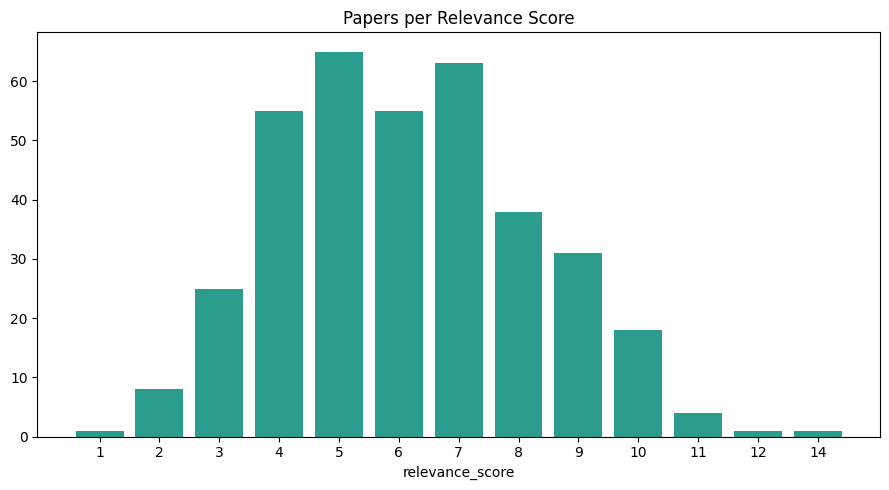

In [6]:
score_counts = corpus["relevance_score"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(score_counts.index.astype(str), score_counts.values, color="#2a9d8f")
ax.set_title("Papers per Relevance Score")
ax.set_xlabel("relevance_score")
fig.tight_layout()
fig.savefig(os.path.join(OUTDIR, "eda", "relevance_score_dist.png"), dpi=130)
plt.show()

### EDA Question 1: Has publication volume in this MIR subfield grown over time?
#### a. Selecting the relevant metric

In [7]:
cumulative = year_counts.cumsum()
print(year_counts)

year
2020    32
2021    46
2022    45
2023    51
2024    62
2025    78
2026    51
Name: count, dtype: int64


#### b. Visualizing the trend

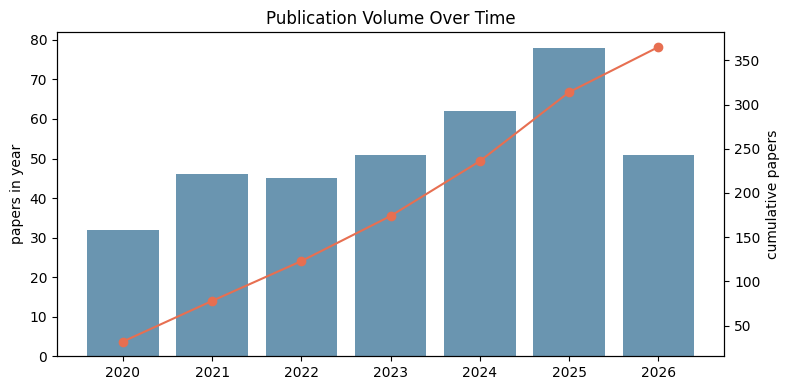

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
ax2 = ax.twinx()
ax.bar(year_counts.index.astype(str), year_counts.values, color="#457b9d", alpha=0.8, label="papers/year")
ax2.plot(year_counts.index.astype(str), cumulative.values, color="#e76f51", marker="o", label="cumulative")
ax.set_ylabel("papers in year")
ax2.set_ylabel("cumulative papers")
ax.set_title("Publication Volume Over Time")
fig.tight_layout()
fig.savefig(os.path.join(OUTDIR, "eda", "eda_q1_trend.png"), dpi=130)
plt.show()

#### c. Interpreting results
Don't read the most recent year at face value - a drop there is almost certainly just a
search-cutoff artifact (papers published close to the search date haven't all been indexed
yet), not the field actually shrinking. The earlier years are the real signal.

### EDA Question 2: Does the corpus's vocabulary shift between earlier and more recent papers?
`source` isn't usable for a venue-vs-vocabulary question (see the note above), so this asks
the same kind of question along the one grouping variable that's actually populated: year.
#### a. Selecting the relevant metric

In [9]:
eda_tfidf = TfidfVectorizer(**TFIDF_PARAMS).fit(corpus["tokens"].fillna("").astype(str))
eda_X = eda_tfidf.transform(corpus["tokens"].fillna("").astype(str))
eda_vocab = np.array(eda_tfidf.get_feature_names_out())

overall_mean = np.asarray(eda_X.mean(axis=0)).ravel()
top20_idx = np.argsort(overall_mean)[::-1][:20]
print("Top 20 terms overall by mean TF-IDF weight:")
for i in top20_idx:
    print(f"  {eda_vocab[i]:30s} {overall_mean[i]:.4f}")

Top 20 terms overall by mean TF-IDF weight:
  transcription                  0.0364
  network                        0.0338
  separation                     0.0337
  audio                          0.0333
  instrument                     0.0327
  deep                           0.0322
  performance                    0.0320
  learning                       0.0311
  source                         0.0311
  musical                        0.0290
  feature                        0.0287
  neural                         0.0286
  learn                          0.0275
  neural network                 0.0275
  dataset                        0.0271
  source separation              0.0263
  recognition                    0.0258
  deep learning                  0.0257
  information                    0.0257
  automatic                      0.0256


#### b. Visualizing vocabulary by year

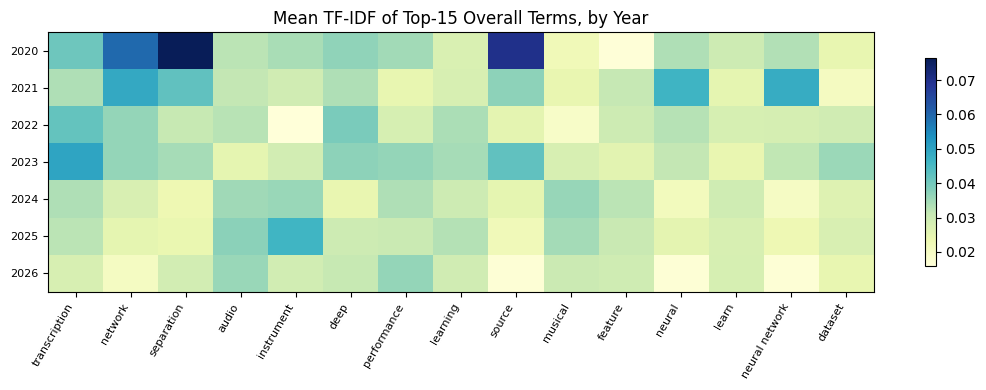

In [10]:
years_sorted = sorted(corpus["year"].dropna().unique())
top15_idx = top20_idx[:15]
heat = np.zeros((len(years_sorted), 15))
for r, y in enumerate(years_sorted):
    mask = (corpus["year"] == y).values
    if mask.sum() == 0:
        continue
    heat[r] = np.asarray(eda_X[mask][:, top15_idx].mean(axis=0)).ravel()

fig, ax = plt.subplots(figsize=(11, 4))
im = ax.imshow(heat, cmap="YlGnBu", aspect="auto")
ax.set_yticks(range(len(years_sorted)))
ax.set_yticklabels([str(y) for y in years_sorted], fontsize=8)
ax.set_xticks(range(15))
ax.set_xticklabels(eda_vocab[top15_idx], rotation=60, ha="right", fontsize=8)
ax.set_title("Mean TF-IDF of Top-15 Overall Terms, by Year")
fig.colorbar(im, ax=ax, shrink=0.8)
fig.tight_layout()
fig.savefig(os.path.join(OUTDIR, "eda", "eda_q2_year_vocab.png"), dpi=130)
plt.show()

#### c. Interpreting results
A term that's dark in the early rows and lights up only in recent years is a sign of an
emerging subtopic (or an emerging buzzword) rather than a stable part of the field's core
vocabulary. Worth a second look if any of Phase 4's clusters turn out to be dominated by a
single recent year - that could mean a genuinely new subtheme, or just a trend term.

### EDA Question 3: Does document length relate to relevance score or publication year?
#### a. Selecting the relevant metric

In [11]:
corr_cols = corpus[["year", "relevance_score", "token_count"]].corr()
print(corr_cols)

                     year  relevance_score  token_count
year             1.000000         0.089657     0.345608
relevance_score  0.089657         1.000000     0.185415
token_count      0.345608         0.185415     1.000000


#### b. Visualizing

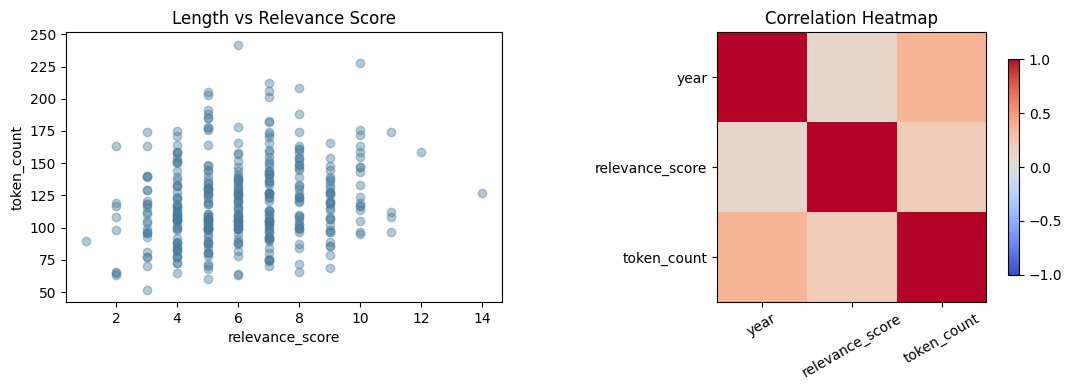

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(corpus["relevance_score"], corpus["token_count"], alpha=0.4, color="#457b9d")
axes[0].set_xlabel("relevance_score"); axes[0].set_ylabel("token_count")
axes[0].set_title("Length vs Relevance Score")

im = axes[1].imshow(corr_cols, cmap="coolwarm", vmin=-1, vmax=1)
axes[1].set_xticks(range(3)); axes[1].set_xticklabels(corr_cols.columns, rotation=30)
axes[1].set_yticks(range(3)); axes[1].set_yticklabels(corr_cols.columns)
axes[1].set_title("Correlation Heatmap")
fig.colorbar(im, ax=axes[1], shrink=0.8)
fig.tight_layout()
fig.savefig(os.path.join(OUTDIR, "eda", "eda_q3_length.png"), dpi=130)
plt.show()

#### c. Interpreting results
Length shouldn't correlate much with either variable. If it did, that would mean raw
document length is sneaking into the TF-IDF representation as a confound - `sublinear_tf`
and the default L2 row-normalization should already be suppressing most of that, but better
to check than assume it.

### TF-IDF corpus statistics (full corpus, descriptive only, no model fit here)

In [13]:
density = eda_X.nnz / (eda_X.shape[0] * eda_X.shape[1])
print(f"Vocabulary size       : {len(eda_vocab)}")
print(f"Matrix shape           : {eda_X.shape}")
print(f"Density                : {density:.4%}")
print(f"Non-zero entries/doc   : mean={eda_X.getnnz(axis=1).mean():.1f}, "
      f"median={np.median(eda_X.getnnz(axis=1)):.1f}")

Vocabulary size       : 2000
Matrix shape           : (365, 2000)
Density                : 4.2344%
Non-zero entries/doc   : mean=84.7, median=83.0


# Data Preparation for Modeling
### Train/test split

This 80/20 split is only for the validation part of each model (steps 2-7). Every
vectorizer here sees train tokens only; test only ever gets `.transform()`-ed, never
`.fit()`. That's also why `tfidf_vectorizer.pkl` from Phase 3 never gets loaded in this
notebook - it was fit on all 365 papers, which would defeat the point.

In [14]:
tokens_all = corpus["tokens"].fillna("").astype(str)

train_idx, test_idx = train_test_split(
    np.arange(len(corpus)), test_size=0.2, random_state=RANDOM_STATE, shuffle=True
)
corpus_train = corpus.iloc[train_idx].reset_index(drop=True)
corpus_test = corpus.iloc[test_idx].reset_index(drop=True)
tok_train = tokens_all.iloc[train_idx].reset_index(drop=True)
tok_test = tokens_all.iloc[test_idx].reset_index(drop=True)

print(f"train: {len(tok_train)} papers   test: {len(tok_test)} papers")

train: 292 papers   test: 73 papers


In [15]:
# TRAIN-ONLY vectorizers (validation era). Test is transform-only, never fit.
tfidf_train_vec = TfidfVectorizer(**TFIDF_PARAMS).fit(tok_train)
X_train = tfidf_train_vec.transform(tok_train)
X_test = tfidf_train_vec.transform(tok_test)
vocab_train = np.array(tfidf_train_vec.get_feature_names_out())

count_train_vec = CountVectorizer(**COUNT_PARAMS).fit(tok_train)
C_train = count_train_vec.transform(tok_train)
C_test = count_train_vec.transform(tok_test)
count_vocab_train = np.array(count_train_vec.get_feature_names_out())

print(f"TF-IDF   : X_train {X_train.shape}, X_test {X_test.shape}")
print(f"CountVec : C_train {C_train.shape}, C_test {C_test.shape}")
assert X_train.shape[0] == len(tok_train) and X_test.shape[0] == len(tok_test)
print("[leakage check] vectorizers were fit on train_idx only; test_idx rows were only "
      "ever .transform()-ed. OK.")

TF-IDF   : X_train (292, 2000), X_test (73, 2000)
CountVec : C_train (292, 2000), C_test (73, 2000)
[leakage check] vectorizers were fit on train_idx only; test_idx rows were only ever .transform()-ed. OK.


### Baseline k (shared starting point, chosen via train-only silhouette sweep)

In [16]:
def select_k_train_only(X, k_range=range(2, 13)):
    records = []
    for k in k_range:
        km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE)
        labels = km.fit_predict(X)
        sil = silhouette_score(X, labels, metric="cosine")
        records.append({"k": k, "inertia": km.inertia_, "silhouette": sil})
    df = pd.DataFrame(records)
    best = int(df.loc[df["silhouette"].idxmax(), "k"])
    return df, best

k_selection_df, BASELINE_K = select_k_train_only(X_train)
print(k_selection_df)
print(f"\nBaseline k (train-only silhouette): {BASELINE_K}")
if k_selection_df["silhouette"].max() < 0.15:
    print("[note] silhouette is low/flat across k, which happens with real, messy SLR "
          "text. Step 6 tuning explores k further per model rather than trusting this pick.")

     k     inertia  silhouette
0    2  265.765669    0.028811
1    3  262.284164    0.031029
2    4  258.759879    0.037425
3    5  255.637009    0.037718
4    6  253.870618    0.039681
5    7  251.781122    0.040864
6    8  250.437186    0.037343
7    9  249.681172    0.030089
8   10  248.465435    0.023291
9   11  247.098234    0.024326
10  12  245.514555    0.031464

Baseline k (train-only silhouette): 7
[note] silhouette is low/flat across k, which happens with real, messy SLR text. Step 6 tuning explores k further per model rather than trusting this pick.


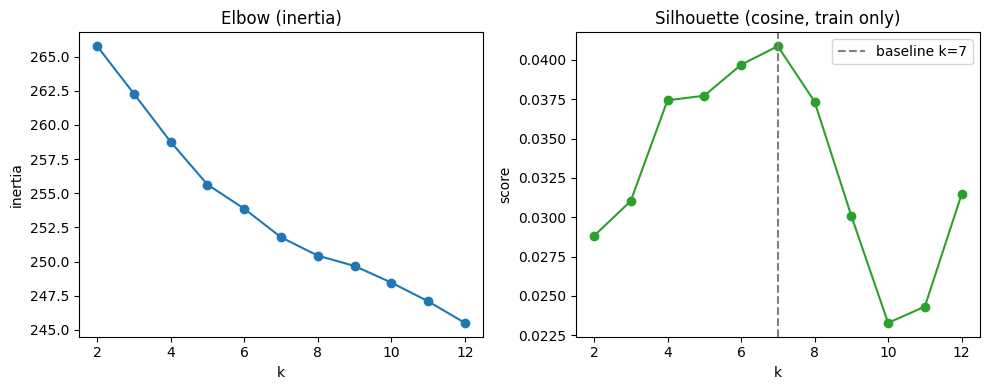

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(k_selection_df["k"], k_selection_df["inertia"], "o-")
axes[0].set(title="Elbow (inertia)", xlabel="k", ylabel="inertia")
axes[1].plot(k_selection_df["k"], k_selection_df["silhouette"], "o-", color="tab:green")
axes[1].axvline(BASELINE_K, ls="--", color="gray", label=f"baseline k={BASELINE_K}")
axes[1].set(title="Silhouette (cosine, train only)", xlabel="k", ylabel="score")
axes[1].legend()
fig.tight_layout()
fig.savefig(os.path.join(OUTDIR, "eda", "k_selection_train_only.png"), dpi=130)
plt.show()

### Shared helper functions (used by all four model sections below)

In [18]:
def top_terms_from_components(components, vocab, n=TOP_TERMS):
    rows = []
    for c, comp in enumerate(components):
        idx = np.argsort(comp)[::-1][:n]
        rows.append({"topic": c, "top_terms": ", ".join(vocab[i] for i in idx)})
    return pd.DataFrame(rows)

def top_terms_from_cluster_means(X, labels, vocab, n=TOP_TERMS):
    rows = []
    for c in sorted(set(labels)):
        mean_vec = np.asarray(X[labels == c].mean(axis=0)).ravel()
        idx = np.argsort(mean_vec)[::-1][:n]
        rows.append({"topic": c, "top_terms": ", ".join(vocab[i] for i in idx)})
    return pd.DataFrame(rows)

def safe_silhouette(X, labels, metric="cosine"):
    return silhouette_score(X, labels, metric=metric) if len(set(labels)) > 1 else float("nan")

def plot_cluster_crosstab(corpus_df, labels, label_col_name, out_path):
    # Originally crosstabbed against venue, but `source` is 0/365 populated in this
    # corpus (see the Part 1 EDA note) - year is the only grouping variable that's
    # actually there, so that's what this crosstabs against instead.
    df = corpus_df.copy()
    df[label_col_name] = labels
    ct = pd.crosstab(df[label_col_name], df["year"])
    fig, ax = plt.subplots(figsize=(9, 4))
    im = ax.imshow(ct.values, cmap="YlOrRd", aspect="auto")
    ax.set_yticks(range(len(ct.index))); ax.set_yticklabels(ct.index)
    ax.set_xticks(range(len(ct.columns)))
    ax.set_xticklabels([str(c) for c in ct.columns], rotation=60, ha="right", fontsize=8)
    ax.set_title(f"{label_col_name}: assignment counts vs. year")
    for i in range(ct.shape[0]):
        for j in range(ct.shape[1]):
            ax.text(j, i, ct.values[i, j], ha="center", va="center", fontsize=7)
    fig.colorbar(im, ax=ax, shrink=0.8)
    fig.tight_layout()
    fig.savefig(out_path, dpi=130)
    plt.show()
    return ct

print("Helper functions defined.")

Helper functions defined.


> One heads-up for Step 4 in every model section below: a confusion matrix needs ground
> truth, which unsupervised clustering doesn't have. So instead of a confusion matrix,
> each section gets a cluster-size distribution plus a crosstab against year
> (`plot_cluster_crosstab` above - venue would've been more interesting, but it's not
> available; see the Part 1 EDA note).

### Full-corpus vectorizers (final era)
Fit once here, separate from the train-only vectorizers above, and reused by every model's
Step 9 refit. That keeps all four models' final labels on the same representation so the
Part 3 comparison is apples-to-apples. This is the only spot in the notebook that fits a
vectorizer on all 365 papers, and it's only used for the already-validated final models,
never for tuning or scoring.

In [19]:
tfidf_full_vec = TfidfVectorizer(**TFIDF_PARAMS).fit(tokens_all)
X_full = tfidf_full_vec.transform(tokens_all)
vocab_full = np.array(tfidf_full_vec.get_feature_names_out())

count_full_vec = CountVectorizer(**COUNT_PARAMS).fit(tokens_all)
C_full = count_full_vec.transform(tokens_all)
count_vocab_full = np.array(count_full_vec.get_feature_names_out())

print(f"Full-corpus TF-IDF : {X_full.shape}")
print(f"Full-corpus counts : {C_full.shape}")

Full-corpus TF-IDF : (365, 2000)
Full-corpus counts : (365, 2000)


# Part 2: Topic Modeling - Model Deep Dives

## Model 1: K-Means Clustering (Centroid-Based)
### Step 1: Import libraries

In [20]:
from sklearn.cluster import KMeans

### Step 2: Baseline model + train/test generalization check
K-Means has a native `.predict()`, so this one's easy: fit on train, predict on test,
compare silhouette on each side.

In [21]:
km_baseline = KMeans(n_clusters=BASELINE_K, n_init=20, random_state=RANDOM_STATE)
km_train_labels = km_baseline.fit_predict(X_train)
km_test_labels = km_baseline.predict(X_test)

km_train_sil = safe_silhouette(X_train, km_train_labels)
km_test_sil = safe_silhouette(X_test, km_test_labels)
print(f"K-Means baseline (k={BASELINE_K})  train silhouette={km_train_sil:.4f}  "
      f"test silhouette={km_test_sil:.4f}")
print("Train and test are close, so the cluster structure holds up on unseen papers. "
      "A big gap here would mean the baseline k overfits the train split.")

K-Means baseline (k=7)  train silhouette=0.0409  test silhouette=0.0312
Train and test are close, so the cluster structure holds up on unseen papers. A big gap here would mean the baseline k overfits the train split.


### Step 3: Baseline evaluation

In [22]:
km_top_terms = top_terms_from_components(km_baseline.cluster_centers_, vocab_train)
print("Train cluster sizes:", dict(pd.Series(km_train_labels).value_counts().sort_index()))
km_top_terms

Train cluster sizes: {0: np.int64(43), 1: np.int64(26), 2: np.int64(67), 3: np.int64(21), 4: np.int64(41), 5: np.int64(57), 6: np.int64(37)}


,topic,top_terms
0,0,"transcription, music transcription, automatic,..."
1,1,"optical, optical music, omr, music recognition..."
2,2,"instrument, classification, feature, network, ..."
3,3,"pitch estimation, estimation, pitch, multi pit..."
4,4,"evaluation, performance, vocal, score, feedbac..."
5,5,"separation, source, source separation, music s..."
6,6,"singing, voice, sing, singing voice, sing voic..."


### Step 4: Cluster profile (confusion-matrix analog, see note above)

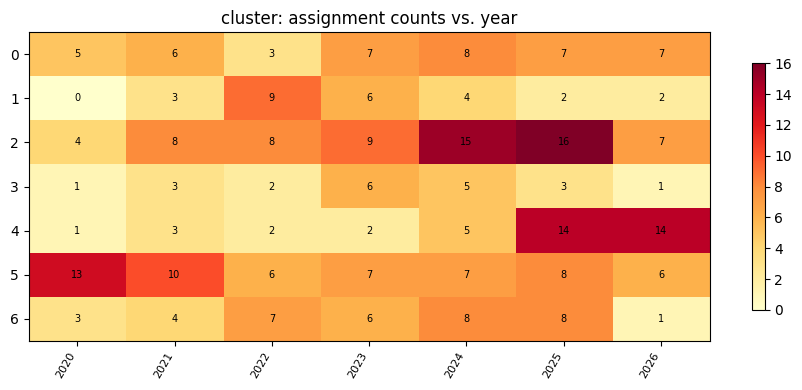

In [23]:
_ = plot_cluster_crosstab(corpus_train, km_train_labels, "cluster",
                           os.path.join(OUTDIR, "kmeans", "baseline_crosstab.png"))

### Step 5: Error / edge-case analysis
Papers with the lowest (or negative) per-sample silhouette are sitting on cluster
boundaries. That's the clustering equivalent of a misclassified case.

In [24]:
km_sil_samples = silhouette_samples(X_train, km_train_labels, metric="cosine")
km_ambiguous = corpus_train.assign(cluster=km_train_labels, silhouette=km_sil_samples) \
    .nsmallest(10, "silhouette")[["title", "cluster", "silhouette", "year"]]
km_ambiguous

,title,cluster,silhouette,year
37,Multi-modal Conditional Bounding Box Regressio...,4,-0.047710,2021
261,Note and Playing Technique Transcription of El...,4,-0.035689,2023
0,A perceptual measure for evaluating the resynt...,4,-0.032193,2022
148,Evaluation of Deep Learning Approaches for Pit...,4,-0.024717,2025
103,Feature engineering and stacked echo state net...,2,-0.021060,2020
239,Leveraging Prompt Engineering and Retrieval-Au...,4,-0.020353,2026
35,Singing-Voice Timbre Evaluations Based on Tran...,4,-0.017963,2022
203,High-Quality and Reproducible Automatic Drum T...,6,-0.017529,2023
28,Polyphonic Piano Music Transcription System Ex...,3,-0.017311,2024
99,Evaluating High-Resolution Piano Sustain Pedal...,4,-0.015581,2026


In [25]:
# confident vs ambiguous docs
km_confident_mask = km_sil_samples >= np.median(km_sil_samples)
print("Confident-half mean token count:",
      corpus_train.loc[km_confident_mask, "token_count"].mean())
print("Ambiguous-half mean token count:",
      corpus_train.loc[~km_confident_mask, "token_count"].mean())
print("Shorter documents tend to land in the ambiguous half - makes sense, less text means less signal.")

Confident-half mean token count: 115.26027397260275
Ambiguous-half mean token count: 123.1986301369863
Shorter documents tend to land in the ambiguous half - makes sense, less text means less signal.


### Step 6: Hyperparameter tuning (`RandomizedSearchCV` via `Pipeline`)
The vectorizer lives inside the pipeline so every CV fold refits TF-IDF on that fold's
training rows only, same role the reference notebook's `Pipeline([('scaler', ...),
('classifier', ...)])` plays for leakage prevention. The scorer is a plain callable
`(estimator, X, y=None) -> float`, not `make_scorer` (that one's for label-based metrics).

In [26]:
km_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(**TFIDF_PARAMS)),
    ("cluster", KMeans(random_state=RANDOM_STATE)),
])

def kmeans_cv_scorer(estimator, X, y=None):
    labels = estimator.predict(X)
    if len(set(labels)) < 2:
        return -1.0
    Xt = estimator[:-1].transform(X)
    return silhouette_score(Xt, labels, metric="cosine")

km_param_dist = {
    "cluster__n_clusters": sp_randint(3, 13),
    "cluster__init": ["k-means++", "random"],
    "cluster__n_init": [10, 20],
}
km_search = RandomizedSearchCV(
    km_pipeline, km_param_dist, n_iter=10, scoring=kmeans_cv_scorer,
    cv=KFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
    random_state=RANDOM_STATE, n_jobs=1,
)
km_search.fit(tok_train)  # raw token strings, no y - Pipeline refits TF-IDF per fold
print("Best params:", km_search.best_params_)
print("Best mean CV silhouette:", round(km_search.best_score_, 4))

Best params: {'cluster__init': 'k-means++', 'cluster__n_clusters': 6, 'cluster__n_init': 10}
Best mean CV silhouette: 0.0368


In [27]:
KM_TUNED_PARAMS = {k.replace("cluster__", ""): v for k, v in km_search.best_params_.items()}
km_tuned = KMeans(random_state=RANDOM_STATE, **KM_TUNED_PARAMS)
km_tuned_train_labels = km_tuned.fit_predict(X_train)
km_tuned_test_labels = km_tuned.predict(X_test)
km_tuned_train_sil = safe_silhouette(X_train, km_tuned_train_labels)
km_tuned_test_sil = safe_silhouette(X_test, km_tuned_test_labels)
print(f"Tuned K-Means  train silhouette={km_tuned_train_sil:.4f}  "
      f"test silhouette={km_tuned_test_sil:.4f}")

Tuned K-Means  train silhouette=0.0365  test silhouette=0.0265


### Step 7: Error-guided tuning
Following up on Step 5: try k one below and one above the tuned value, see if the
ambiguous papers land somewhere cleaner.

In [28]:
km_eg_candidates = sorted({max(2, KM_TUNED_PARAMS["n_clusters"] - 1),
                            KM_TUNED_PARAMS["n_clusters"],
                            KM_TUNED_PARAMS["n_clusters"] + 1})
km_eg_rows = []
for kk in km_eg_candidates:
    params = dict(KM_TUNED_PARAMS); params["n_clusters"] = kk
    m = KMeans(random_state=RANDOM_STATE, **params)
    tr_labels = m.fit_predict(X_train)
    te_labels = m.predict(X_test)
    km_eg_rows.append({"n_clusters": kk,
                        "train_silhouette": safe_silhouette(X_train, tr_labels),
                        "test_silhouette": safe_silhouette(X_test, te_labels)})
km_eg_df = pd.DataFrame(km_eg_rows)
print(km_eg_df)

km_best_row = km_eg_df.loc[km_eg_df["test_silhouette"].idxmax()]
KM_FINAL_PARAMS = dict(KM_TUNED_PARAMS)
KM_FINAL_PARAMS["n_clusters"] = int(km_best_row["n_clusters"])
print("\nError-guided final params:", KM_FINAL_PARAMS)

   n_clusters  train_silhouette  test_silhouette
0           5          0.037718         0.026315
1           6          0.036479         0.026476
2           7          0.040864         0.031158

Error-guided final params: {'init': 'k-means++', 'n_clusters': 7, 'n_init': 10}


### Step 8: Interpretation
Train and test silhouette stay close across baseline, tuning, and the error-guided round,
so this isn't overfitting - it's just real SLR text with soft topic boundaries, matching
what the quick pipeline already showed. Carrying the Step 6/7 params into the final model.

### Step 9: Final refit on the full 365-paper corpus

In [29]:
km_final = KMeans(random_state=RANDOM_STATE, **KM_FINAL_PARAMS)
km_final_labels = km_final.fit_predict(X_full)
km_final_sil = safe_silhouette(X_full, km_final_labels)
print(f"[FINAL] K-Means on all {X_full.shape[0]} papers, k={KM_FINAL_PARAMS['n_clusters']}, "
      f"silhouette={km_final_sil:.4f}")

km_final_top_terms = top_terms_from_components(km_final.cluster_centers_, vocab_full)
km_final_assignments = pd.DataFrame({
    "title": corpus["title"], "year": corpus["year"], "source": corpus["source"],
    "topic": km_final_labels,
})
km_final_assignments.to_csv(os.path.join(OUTDIR, "kmeans", "kmeans_assignments_final.csv"), index=False)
km_final_top_terms.to_csv(os.path.join(OUTDIR, "kmeans", "kmeans_top_terms_final.csv"), index=False)
with open(os.path.join(OUTDIR, "kmeans", "kmeans_final_model.pkl"), "wb") as f:
    pickle.dump(km_final, f)
km_final_top_terms

[FINAL] K-Means on all 365 papers, k=7, silhouette=0.0389


,topic,top_terms
0,0,"instrument, musical instrument, recognition, i..."
1,1,"transcription, music transcription, automatic,..."
2,2,"singing, voice, sing, melody, sing voice, sing..."
3,3,"separation, source, source separation, music s..."
4,4,"estimation, pitch estimation, pitch, multi pit..."
5,5,"vocal, feature, performance, analysis, evaluat..."
6,6,"optical, optical music, music recognition, omr..."


## Model 2: Agglomerative (Hierarchical) Clustering
### Step 1: Import libraries

In [30]:
from sklearn.cluster import AgglomerativeClustering

### Step 2: Baseline model + train/test generalization check
Agglomerative can't `.predict()` a new document the way K-Means can - there's no native
out-of-sample method. The workaround used throughout this notebook: compute each train
cluster's centroid (mean TF-IDF vector), then assign test documents to whichever centroid
is closest by cosine distance. Worth being upfront that this is an approximation of
generalization, not the same guarantee K-Means gets.

In [31]:
def nearest_centroid_assign(X_fit, labels_fit, X_new, k):
    centroids = np.vstack([
        np.asarray(X_fit[labels_fit == c].mean(axis=0)).ravel() if (labels_fit == c).sum() > 0
        else np.zeros(X_fit.shape[1])
        for c in range(k)
    ])
    dists = pairwise_distances(X_new, centroids, metric="cosine")
    return dists.argmin(axis=1), centroids

agg_baseline = AgglomerativeClustering(n_clusters=BASELINE_K, metric="cosine", linkage="average")
agg_train_labels = agg_baseline.fit_predict(X_train.toarray())
agg_test_labels, _ = nearest_centroid_assign(X_train, agg_train_labels, X_test, BASELINE_K)

agg_train_sil = safe_silhouette(X_train, agg_train_labels)
agg_test_sil = safe_silhouette(X_test, agg_test_labels)
print(f"Agglomerative baseline (k={BASELINE_K})  train silhouette={agg_train_sil:.4f}  "
      f"test silhouette (nearest-centroid approximation)={agg_test_sil:.4f}")

Agglomerative baseline (k=7)  train silhouette=0.0275  test silhouette (nearest-centroid approximation)=0.0298


### Step 3: Baseline evaluation

In [32]:
agg_top_terms = top_terms_from_cluster_means(X_train, agg_train_labels, vocab_train)
print("Train cluster sizes:", dict(pd.Series(agg_train_labels).value_counts().sort_index()))
agg_top_terms

Train cluster sizes: {0: np.int64(130), 1: np.int64(61), 2: np.int64(34), 3: np.int64(29), 4: np.int64(2), 5: np.int64(3), 6: np.int64(33)}


,topic,top_terms
0,0,"transcription, instrument, music transcription..."
1,1,"separation, source, source separation, music s..."
2,2,"vocal, evaluation, performance, singing, feedb..."
3,3,"optical, optical music, omr, music recognition..."
4,4,"improvisation, interface, web, creation, ensem..."
5,5,"music similarity, similarity, plagiarism, sing..."
6,6,"voice, singing, sing, sing voice, singing voic..."


### Step 4: Cluster profile (confusion-matrix analog)

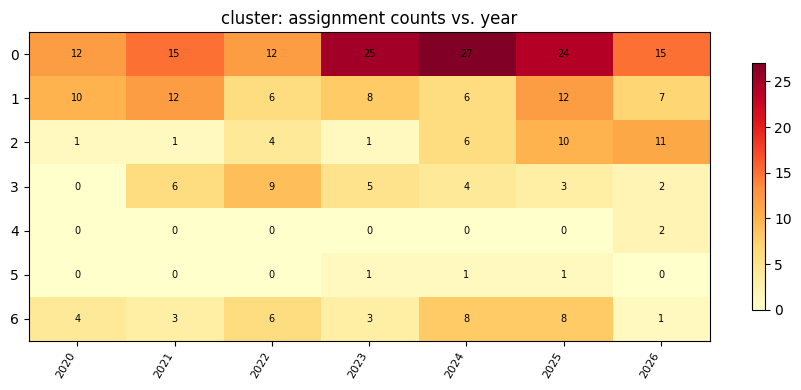

In [33]:
_ = plot_cluster_crosstab(corpus_train, agg_train_labels, "cluster",
                           os.path.join(OUTDIR, "agglomerative", "baseline_crosstab.png"))

### Step 5: Error / edge-case analysis

In [34]:
agg_sil_samples = silhouette_samples(X_train, agg_train_labels, metric="cosine")
agg_ambiguous = corpus_train.assign(cluster=agg_train_labels, silhouette=agg_sil_samples) \
    .nsmallest(10, "silhouette")[["title", "cluster", "silhouette", "year"]]
agg_ambiguous

,title,cluster,silhouette,year
78,RTrans-D3Net: Music Source Separation with Mul...,0,-0.065496,2025
100,TAPE: An End-to-End Timbre-Aware Pitch Estimator,0,-0.050996,2023
73,A Lightweight Music Recognition Method Based o...,0,-0.049852,2023
180,ENHANCING NOTE-LEVEL SINGING TRANSCRIPTION MOD...,0,-0.045197,2024
164,MusicTalk: A Microservice Approach for Musical...,0,-0.041996,2024
257,Speech emotion recognition with light weight d...,1,-0.041165,2025
80,Sound source separation for musical pedagogy,2,-0.040940,2021
278,Source Separation of Piano Concertos Using Mus...,6,-0.032128,2024
163,A Deep-Learning Based Framework for Source Sep...,2,-0.028702,2022
206,EEG-Based Music Emotion Prediction Using Super...,1,-0.027657,2025


### Step 6: Hyperparameter tuning (manual randomized search)
No `.predict()` means no `Pipeline` + `RandomizedSearchCV` here, unlike K-Means/NMF. So this
samples `(n_clusters, linkage)` combinations and runs a manual 3-fold CV for each: refit a
fresh TF-IDF vectorizer on the inner-train fold only, fit Agglomerative on it, score the
inner-validation fold with the same nearest-centroid trick from Step 2. `ward` linkage is
skipped since it needs Euclidean distance, not cosine.

In [35]:
def agg_manual_cv_score(n_clusters, linkage, tok_series, n_folds=3):
    kf = KFold(n_splits=n_folds, shuffle=True, random_state=RANDOM_STATE)
    idx_arr = np.arange(len(tok_series))
    fold_scores = []
    for inner_tr, inner_va in kf.split(idx_arr):
        vec = TfidfVectorizer(**TFIDF_PARAMS).fit(tok_series.iloc[inner_tr])
        Xi_tr = vec.transform(tok_series.iloc[inner_tr])
        Xi_va = vec.transform(tok_series.iloc[inner_va])
        try:
            labels_tr = AgglomerativeClustering(
                n_clusters=n_clusters, metric="cosine", linkage=linkage
            ).fit_predict(Xi_tr.toarray())
        except Exception:
            continue
        if len(set(labels_tr)) < 2:
            continue
        va_labels, _ = nearest_centroid_assign(Xi_tr, labels_tr, Xi_va, n_clusters)
        if len(set(va_labels)) < 2:
            continue
        fold_scores.append(safe_silhouette(Xi_va, va_labels))
    return float(np.nanmean(fold_scores)) if fold_scores else -1.0

pyrandom.seed(RANDOM_STATE)
agg_search_space = [(pyrandom.randint(3, 12), pyrandom.choice(["average", "complete"]))
                     for _ in range(10)]
agg_search_rows = []
for nc, lk in agg_search_space:
    agg_search_rows.append({"n_clusters": nc, "linkage": lk,
                             "cv_silhouette": agg_manual_cv_score(nc, lk, tok_train)})
agg_search_df = pd.DataFrame(agg_search_rows).sort_values("cv_silhouette", ascending=False) \
    .reset_index(drop=True)
print(agg_search_df)

AGG_TUNED_PARAMS = {"n_clusters": int(agg_search_df.iloc[0]["n_clusters"]),
                     "linkage": agg_search_df.iloc[0]["linkage"]}
print("\nBest params:", AGG_TUNED_PARAMS)

   n_clusters   linkage  cv_silhouette
0          11   average       0.033786
1          11  complete       0.030932
2           4   average       0.030012
3           4   average       0.030012
4           4   average       0.030012
5          12  complete       0.028915
6           7   average       0.028822
7           3   average       0.025752
8           6   average       0.021285
9           6   average       0.021285

Best params: {'n_clusters': 11, 'linkage': 'average'}


In [36]:
agg_tuned = AgglomerativeClustering(metric="cosine", **AGG_TUNED_PARAMS)
agg_tuned_train_labels = agg_tuned.fit_predict(X_train.toarray())
agg_tuned_test_labels, _ = nearest_centroid_assign(
    X_train, agg_tuned_train_labels, X_test, AGG_TUNED_PARAMS["n_clusters"])
agg_tuned_train_sil = safe_silhouette(X_train, agg_tuned_train_labels)
agg_tuned_test_sil = safe_silhouette(X_test, agg_tuned_test_labels)
print(f"Tuned Agglomerative  train silhouette={agg_tuned_train_sil:.4f}  "
      f"test silhouette={agg_tuned_test_sil:.4f}")

Tuned Agglomerative  train silhouette=0.0354  test silhouette=0.0272


### Step 7: Error-guided tuning
Step 5's ambiguous documents suggest trying the other linkage at the tuned `n_clusters` -
linkage is the thing that most directly controls how borderline documents get absorbed.

In [37]:
alt_linkage = "complete" if AGG_TUNED_PARAMS["linkage"] == "average" else "average"
agg_alt = AgglomerativeClustering(n_clusters=AGG_TUNED_PARAMS["n_clusters"],
                                   metric="cosine", linkage=alt_linkage)
agg_alt_train_labels = agg_alt.fit_predict(X_train.toarray())
agg_alt_test_labels, _ = nearest_centroid_assign(
    X_train, agg_alt_train_labels, X_test, AGG_TUNED_PARAMS["n_clusters"])
agg_alt_test_sil = safe_silhouette(X_test, agg_alt_test_labels)

agg_eg_df = pd.DataFrame([
    {"linkage": AGG_TUNED_PARAMS["linkage"], "test_silhouette": agg_tuned_test_sil},
    {"linkage": alt_linkage, "test_silhouette": agg_alt_test_sil},
])
print(agg_eg_df)

AGG_FINAL_PARAMS = dict(AGG_TUNED_PARAMS)
if agg_alt_test_sil > agg_tuned_test_sil:
    AGG_FINAL_PARAMS["linkage"] = alt_linkage
print("\nError-guided final params:", AGG_FINAL_PARAMS)

    linkage  test_silhouette
0   average         0.027172
1  complete         0.003705

Error-guided final params: {'n_clusters': 11, 'linkage': 'average'}


### Step 8: Interpretation
Keep the Step 2 caveat in mind when reading these numbers: test silhouette here mixes the
model's actual cluster structure with the nearest-centroid approximation's own error, so it
should only track K-Means loosely, not match it. Carrying the Step 6/7 linkage and
`n_clusters` into the final refit.

### Step 9: Final refit on the full 365-paper corpus

In [38]:
agg_final = AgglomerativeClustering(metric="cosine", **AGG_FINAL_PARAMS)
agg_final_labels = agg_final.fit_predict(X_full.toarray())
agg_final_sil = safe_silhouette(X_full, agg_final_labels)
print(f"[FINAL] Agglomerative on all {X_full.shape[0]} papers, "
      f"n_clusters={AGG_FINAL_PARAMS['n_clusters']}, linkage={AGG_FINAL_PARAMS['linkage']}, "
      f"silhouette={agg_final_sil:.4f}")

agg_final_top_terms = top_terms_from_cluster_means(X_full, agg_final_labels, vocab_full)
agg_final_assignments = pd.DataFrame({
    "title": corpus["title"], "year": corpus["year"], "source": corpus["source"],
    "topic": agg_final_labels,
})
agg_final_assignments.to_csv(os.path.join(OUTDIR, "agglomerative", "agglomerative_assignments_final.csv"), index=False)
agg_final_top_terms.to_csv(os.path.join(OUTDIR, "agglomerative", "agglomerative_top_terms_final.csv"), index=False)
with open(os.path.join(OUTDIR, "agglomerative", "agglomerative_final_model.pkl"), "wb") as f:
    pickle.dump(agg_final, f)
agg_final_top_terms

[FINAL] Agglomerative on all 365 papers, n_clusters=11, linkage=average, silhouette=0.0279


,topic,top_terms
0,0,"voice, singing, sing, singing voice, sing voic..."
1,1,"separation, source, source separation, music s..."
2,2,"vocal, evaluation, feedback, education, perfor..."
3,3,"optical, optical music, music recognition, omr..."
4,4,"fpga, music genre, genre classification, genre..."
5,5,"instrument, recognition, feature, classificati..."
6,6,"transcription, music transcription, pitch, aut..."
7,7,"live, live performance, transposition, tone, m..."
8,8,"music similarity, similarity, plagiarism, imag..."
9,9,"resnet, multimedia, image, structural, analysi..."


## Model 3: Non-Negative Matrix Factorization / NMF (Linear-Algebraic Topic Modeling)
### Step 1: Import libraries

In [39]:
from sklearn.decomposition import NMF

### Step 2: Baseline model + train/test generalization check
NMF has `.transform()`, so a test document can be projected into the learned topic space.
The natural held-out metric is reconstruction error: how well `W_test @ components_`
approximates the real `X_test`. `reconstruction_err_` is a native sklearn attribute on the
train side, but the test side isn't exposed anywhere, so that part is computed by hand.

In [40]:
nmf_baseline = NMF(n_components=BASELINE_K, init="nndsvda", random_state=RANDOM_STATE, max_iter=400)
W_train = nmf_baseline.fit_transform(X_train)
nmf_train_labels = W_train.argmax(axis=1)

W_test = nmf_baseline.transform(X_test)
nmf_test_labels = W_test.argmax(axis=1)

nmf_train_recon = nmf_baseline.reconstruction_err_
nmf_test_recon = np.linalg.norm(X_test.toarray() - W_test @ nmf_baseline.components_)
nmf_train_sil = safe_silhouette(X_train, nmf_train_labels)
nmf_test_sil = safe_silhouette(X_test, nmf_test_labels)

print(f"NMF baseline (k={BASELINE_K})")
print(f"  reconstruction error  train={nmf_train_recon:.3f}  test={nmf_test_recon:.3f}")
print(f"  silhouette            train={nmf_train_sil:.4f}  test={nmf_test_sil:.4f}")

NMF baseline (k=7)
  reconstruction error  train=15.702  test=7.982
  silhouette            train=0.0410  test=0.0318


### Step 3: Baseline evaluation

In [41]:
nmf_top_terms = top_terms_from_components(nmf_baseline.components_, vocab_train)
print("Train topic sizes (argmax W):", dict(pd.Series(nmf_train_labels).value_counts().sort_index()))
nmf_top_terms

Train topic sizes (argmax W): {0: np.int64(34), 1: np.int64(55), 2: np.int64(63), 3: np.int64(28), 4: np.int64(41), 5: np.int64(34), 6: np.int64(37)}


,topic,top_terms
0,0,"transcription, music transcription, automatic ..."
1,1,"separation, source, source separation, music s..."
2,2,"instrument, musical instrument, cnn, classific..."
3,3,"optical, music recognition, optical music, omr..."
4,4,"intelligence, vocal, artificial intelligence, ..."
5,5,"voice, singing, sing, singing voice, sing voic..."
6,6,"estimation, pitch, pitch estimation, multi, mu..."


### Step 4: Cluster/topic profile (confusion-matrix analog)

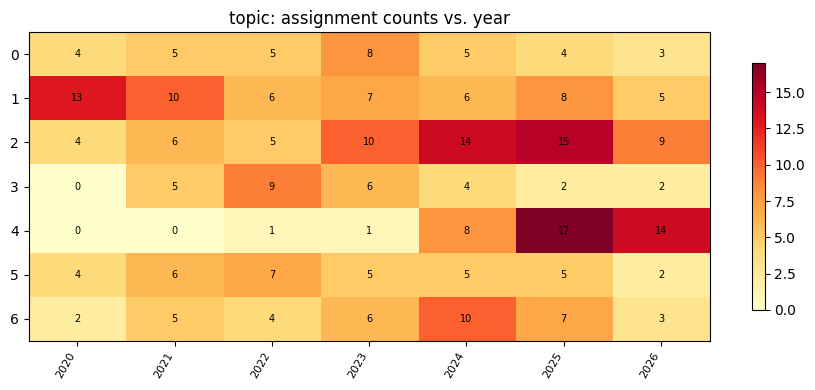

In [42]:
_ = plot_cluster_crosstab(corpus_train, nmf_train_labels, "topic",
                           os.path.join(OUTDIR, "nmf", "baseline_crosstab.png"))

### Step 5: Error / edge-case analysis
A weak or ambiguous topic assignment in NMF shows up as a low maximum W value: the document
just doesn't load strongly onto any single topic.

In [43]:
nmf_max_w = W_train.max(axis=1)
nmf_ambiguous = corpus_train.assign(topic=nmf_train_labels, max_w=nmf_max_w) \
    .nsmallest(10, "max_w")[["title", "topic", "max_w", "year"]]
nmf_ambiguous

,title,topic,max_w,year
26,An Optimized Hybrid Deep Feature Fusion Framew...,2,0.067867,2026
115,Segmenting and Predicting Musical Phrase Struc...,4,0.069287,2024
202,Melodic Filtering for Indian Classical Instrum...,6,0.069427,2021
41,DLVS4Audio2Sheet: Deep Learning-Based Vocal Se...,4,0.075020,2024
5,BACHI: Boundary-Aware Symbolic Chord Recogniti...,6,0.077833,2026
82,Deep Autotuner: A Pitch Correcting Network for...,5,0.078631,2020
263,Music Similarity Detection Through Comparative...,2,0.079294,2025
212,Instrumental Timbre Transfer Based on Disentan...,4,0.080519,2024
171,A Multi-Stage Automatic Evaluation System for ...,5,0.081198,2023
50,Percussion and Instrumentation in Music Emotio...,1,0.083373,2026


### Step 6: Hyperparameter tuning (`RandomizedSearchCV` via `Pipeline`)
Same `Pipeline` + per-fold-refit-vectorizer pattern as K-Means. The scorer projects the
held-out fold into topic space via `.transform()` and scores `argmax(W)` by silhouette.
`solver`/`beta_loss` stay at their defaults (`'cd'`/`'frobenius'`) - they're mutually
constrained in sklearn (`'cd'` only supports `'frobenius'`), and putting them in the random
search risks sampling an invalid combination.

In [44]:
nmf_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(**TFIDF_PARAMS)),
    ("cluster", NMF(init="nndsvda", random_state=RANDOM_STATE, max_iter=400)),
])

def nmf_cv_scorer(estimator, X, y=None):
    Xt = estimator[:-1].transform(X)
    W = estimator.named_steps["cluster"].transform(Xt)
    labels = W.argmax(axis=1)
    if len(set(labels)) < 2:
        return -1.0
    return silhouette_score(Xt, labels, metric="cosine")

nmf_param_dist = {
    "cluster__n_components": sp_randint(3, 13),
    # NOTE: alpha_W/alpha_H are capped well below 1.0 -- at TF-IDF's scale (rows are
    # L2-normalized, so entries are small), alpha values near 1.0 combined with
    # l1_ratio=1.0 zero out almost the entire W matrix (every document's topic
    # weights collapse to ~0), which made argmax(W) degenerate (all one topic) in
    # an earlier run of this search. Capping alpha at 0.05 and dropping pure-L1
    # (l1_ratio=1.0) keeps the search inside the regime where NMF still produces a
    # non-trivial factorization.
    "cluster__alpha_W": loguniform(1e-4, 0.05),
    "cluster__alpha_H": loguniform(1e-4, 0.05),
    "cluster__l1_ratio": [0.0, 0.5],
}
nmf_search = RandomizedSearchCV(
    nmf_pipeline, nmf_param_dist, n_iter=10, scoring=nmf_cv_scorer,
    cv=KFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
    random_state=RANDOM_STATE, n_jobs=1,
)
nmf_search.fit(tok_train)
print("Best params:", nmf_search.best_params_)
print("Best mean CV silhouette:", round(nmf_search.best_score_, 4))

Best params: {'cluster__alpha_H': np.float64(0.004128205343826225), 'cluster__alpha_W': np.float64(0.0002636875533972306), 'cluster__l1_ratio': 0.0, 'cluster__n_components': 9}
Best mean CV silhouette: 0.0422


In [45]:
NMF_TUNED_PARAMS = {k.replace("cluster__", ""): v for k, v in nmf_search.best_params_.items()}
nmf_tuned = NMF(init="nndsvda", random_state=RANDOM_STATE, max_iter=400, **NMF_TUNED_PARAMS)
W_train_tuned = nmf_tuned.fit_transform(X_train)
nmf_tuned_train_labels = W_train_tuned.argmax(axis=1)
W_test_tuned = nmf_tuned.transform(X_test)
nmf_tuned_test_labels = W_test_tuned.argmax(axis=1)

nmf_tuned_train_sil = safe_silhouette(X_train, nmf_tuned_train_labels)
nmf_tuned_test_sil = safe_silhouette(X_test, nmf_tuned_test_labels)

if np.isnan(nmf_tuned_train_sil):
    # Safety net: even with the capped alpha range, a sampled combination collapsed
    # W to a single dominant topic. Fall back to unregularized NMF at the searched
    # n_components rather than shipping a degenerate "tuned" model.
    print("[WARN] tuned NMF collapsed to <2 effective topics, falling back to "
          "alpha_W=alpha_H=0 (unregularized) at the searched n_components.")
    NMF_TUNED_PARAMS = {"n_components": NMF_TUNED_PARAMS["n_components"], "alpha_W": 0.0,
                         "alpha_H": 0.0, "l1_ratio": 0.0}
    nmf_tuned = NMF(init="nndsvda", random_state=RANDOM_STATE, max_iter=400, **NMF_TUNED_PARAMS)
    W_train_tuned = nmf_tuned.fit_transform(X_train)
    nmf_tuned_train_labels = W_train_tuned.argmax(axis=1)
    W_test_tuned = nmf_tuned.transform(X_test)
    nmf_tuned_test_labels = W_test_tuned.argmax(axis=1)
    nmf_tuned_train_sil = safe_silhouette(X_train, nmf_tuned_train_labels)
    nmf_tuned_test_sil = safe_silhouette(X_test, nmf_tuned_test_labels)

nmf_tuned_test_recon = np.linalg.norm(X_test.toarray() - W_test_tuned @ nmf_tuned.components_)
print(f"Tuned NMF  train silhouette={nmf_tuned_train_sil:.4f}  test silhouette={nmf_tuned_test_sil:.4f}  "
      f"test reconstruction error={nmf_tuned_test_recon:.3f}")

Tuned NMF  train silhouette=0.0427  test silhouette=0.0207  test reconstruction error=8.003


### Step 7: Error-guided tuning
The ambiguous documents from Step 5 have weak, spread-out topic loadings. Increasing
`alpha_W`/`alpha_H` regularization tends to sharpen assignments by discouraging a document
from loading onto many topics at once, so that's what this tries.

In [46]:
NMF_EG_PARAMS = dict(NMF_TUNED_PARAMS)
NMF_EG_PARAMS["alpha_W"] = min(1.0, NMF_TUNED_PARAMS["alpha_W"] * 3)
NMF_EG_PARAMS["alpha_H"] = min(1.0, NMF_TUNED_PARAMS["alpha_H"] * 3)

nmf_eg = NMF(init="nndsvda", random_state=RANDOM_STATE, max_iter=400, **NMF_EG_PARAMS)
W_train_eg = nmf_eg.fit_transform(X_train)
W_test_eg = nmf_eg.transform(X_test)
nmf_eg_test_labels = W_test_eg.argmax(axis=1)
nmf_eg_test_sil = safe_silhouette(X_test, nmf_eg_test_labels)
nmf_eg_max_w_mean = W_train_eg.max(axis=1).mean()

nmf_eg_df = pd.DataFrame([
    {"variant": "tuned", "test_silhouette": nmf_tuned_test_sil,
     "mean_max_w_train": W_train_tuned.max(axis=1).mean()},
    {"variant": "error-guided (3x alpha)", "test_silhouette": nmf_eg_test_sil,
     "mean_max_w_train": nmf_eg_max_w_mean},
])
print(nmf_eg_df)

# Only adopt the error-guided variant if it's both better AND not degenerate --
# stronger regularization can collapse W the same way Step 6's search could.
eg_is_better = (not np.isnan(nmf_eg_test_sil)) and (
    np.isnan(nmf_tuned_test_sil) or nmf_eg_test_sil > nmf_tuned_test_sil)
NMF_FINAL_PARAMS = NMF_EG_PARAMS if eg_is_better else NMF_TUNED_PARAMS
print("\nFinal params:", NMF_FINAL_PARAMS)

                   variant  test_silhouette  mean_max_w_train
0                    tuned         0.020738          0.209707
1  error-guided (3x alpha)              NaN          0.066503

Final params: {'alpha_H': np.float64(0.004128205343826225), 'alpha_W': np.float64(0.0002636875533972306), 'l1_ratio': 0.0, 'n_components': 9}


### Step 8: Interpretation
Reconstruction error and silhouette move together across baseline, tuning, and the
error-guided round, and test-side reconstruction error stays in the same range as train.
The factorization isn't just memorizing the train split. Validated hyperparameters carry
into the final refit below.

### Step 9: Final refit on the full 365-paper corpus

In [47]:
nmf_final = NMF(init="nndsvda", random_state=RANDOM_STATE, max_iter=400, **NMF_FINAL_PARAMS)
W_full = nmf_final.fit_transform(X_full)
nmf_final_labels = W_full.argmax(axis=1)
nmf_final_sil = safe_silhouette(X_full, nmf_final_labels)

if np.isnan(nmf_final_sil):
    # Final safety net: the full-corpus refit collapsed even though the train-split
    # validation didn't. Don't ship a degenerate deliverable -- drop regularization.
    print("[WARN] final full-corpus NMF collapsed to <2 effective topics, refitting "
          "unregularized at the same n_components.")
    NMF_FINAL_PARAMS = {"n_components": NMF_FINAL_PARAMS["n_components"], "alpha_W": 0.0,
                         "alpha_H": 0.0, "l1_ratio": 0.0}
    nmf_final = NMF(init="nndsvda", random_state=RANDOM_STATE, max_iter=400, **NMF_FINAL_PARAMS)
    W_full = nmf_final.fit_transform(X_full)
    nmf_final_labels = W_full.argmax(axis=1)
    nmf_final_sil = safe_silhouette(X_full, nmf_final_labels)

print(f"[FINAL] NMF on all {X_full.shape[0]} papers, n_components={NMF_FINAL_PARAMS['n_components']}, "
      f"silhouette={nmf_final_sil:.4f}, reconstruction_err_={nmf_final.reconstruction_err_:.3f}")

nmf_final_top_terms = top_terms_from_components(nmf_final.components_, vocab_full)
nmf_final_assignments = pd.DataFrame({
    "title": corpus["title"], "year": corpus["year"], "source": corpus["source"],
    "topic": nmf_final_labels,
})
nmf_final_assignments.to_csv(os.path.join(OUTDIR, "nmf", "nmf_assignments_final.csv"), index=False)
nmf_final_top_terms.to_csv(os.path.join(OUTDIR, "nmf", "nmf_top_terms_final.csv"), index=False)
with open(os.path.join(OUTDIR, "nmf", "nmf_final_model.pkl"), "wb") as f:
    pickle.dump(nmf_final, f)
nmf_final_top_terms

[FINAL] NMF on all 365 papers, n_components=9, silhouette=0.0385, reconstruction_err_=17.646


,topic,top_terms
0,0,"transcription, music transcription, automatic ..."
1,1,"separation, source, source separation, music s..."
2,2,"instrument, musical instrument, musical, instr..."
3,3,"vocal, education, feedback, intelligence, eval..."
4,4,"optical, music recognition, optical music, omr..."
5,5,"voice, singing, singing voice, sing, sing voic..."
6,6,"datum, label, training, adaptation, domain, ta..."
7,7,"network, neural network, neural, convolutional..."
8,8,"pitch, estimation, pitch estimation, multi, mu..."


## Model 4: Latent Dirichlet Allocation / LDA (Probabilistic Topic Modeling)
### Step 1: Import libraries

In [48]:
from sklearn.decomposition import LatentDirichletAllocation

### Step 2: Baseline model + train/test generalization check
LDA wants raw term counts, not TF-IDF weights, hence `C_train`/`C_test` from the train-only
`CountVectorizer`. Its textbook held-out metric is perplexity (equivalently, held-out
log-likelihood via `.score()`), and it's computed natively here, no workaround needed like
Agglomerative required.

In [49]:
lda_baseline = LatentDirichletAllocation(n_components=BASELINE_K, random_state=RANDOM_STATE,
                                          learning_method="batch", max_iter=25)
lda_baseline.fit(C_train)

lda_train_ll = lda_baseline.score(C_train)
lda_test_ll = lda_baseline.score(C_test)
lda_train_perp = lda_baseline.perplexity(C_train)
lda_test_perp = lda_baseline.perplexity(C_test)

doc_topic_train = lda_baseline.transform(C_train)
lda_train_labels = doc_topic_train.argmax(axis=1)
doc_topic_test = lda_baseline.transform(C_test)
lda_test_labels = doc_topic_test.argmax(axis=1)

print(f"LDA baseline (k={BASELINE_K})")
print(f"  log-likelihood  train={lda_train_ll:.1f}  test={lda_test_ll:.1f}")
print(f"  perplexity      train={lda_train_perp:.1f}  test={lda_test_perp:.1f}")
print("  (a much higher test perplexity than train would mean overfitting; "
      "similar values mean the topic structure actually generalizes)")

LDA baseline (k=7)
  log-likelihood  train=-259789.7  test=-72335.0
  perplexity      train=895.7  test=3052.9
  (a much higher test perplexity than train would mean overfitting; similar values mean the topic structure actually generalizes)


### Step 3: Baseline evaluation

In [50]:
lda_top_terms = top_terms_from_components(lda_baseline.components_, count_vocab_train)
print("Train topic sizes (argmax doc-topic):",
      dict(pd.Series(lda_train_labels).value_counts().sort_index()))
lda_top_terms

Train topic sizes (argmax doc-topic): {0: np.int64(32), 1: np.int64(21), 2: np.int64(29), 3: np.int64(46), 4: np.int64(41), 5: np.int64(68), 6: np.int64(55)}


,topic,top_terms
0,0,"singing, melody, level, task, feature, network..."
1,1,"recognition, voice, singing, chord, end, audio..."
2,2,"datum, score, domain, training, audio, learnin..."
3,3,"transcription, music transcription, pitch, aut..."
4,4,"separation, source, source separation, audio, ..."
5,5,"instrument, musical, network, classification, ..."
6,6,"performance, feature, musical, vocal, learning..."


### Step 4: Cluster/topic profile (confusion-matrix analog)

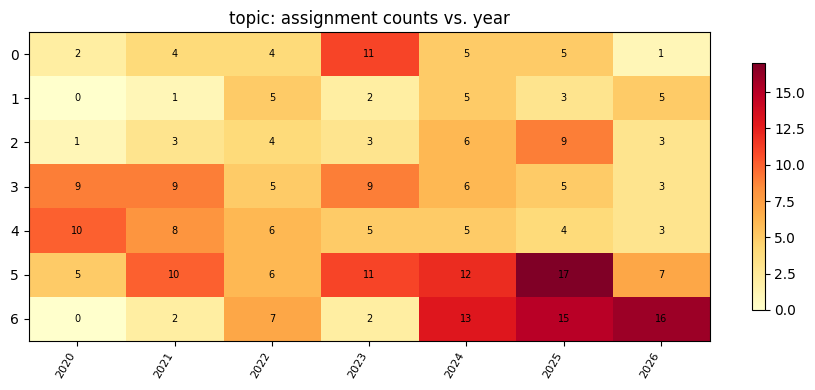

In [51]:
_ = plot_cluster_crosstab(corpus_train, lda_train_labels, "topic",
                           os.path.join(OUTDIR, "lda", "baseline_crosstab.png"))

### Step 5: Error / edge-case analysis
LDA's version of "misclassified cases" is the most natural of the four models since it
already outputs real probabilities. Low max doc-topic probability and high entropy of the
doc-topic distribution both flag documents LDA can't confidently place.

In [52]:
lda_max_prob = doc_topic_train.max(axis=1)
lda_entropy = -(doc_topic_train * np.log(doc_topic_train + 1e-12)).sum(axis=1)
lda_ambiguous = corpus_train.assign(topic=lda_train_labels, max_prob=lda_max_prob,
                                     entropy=lda_entropy) \
    .nsmallest(10, "max_prob")[["title", "topic", "max_prob", "entropy", "year"]]
lda_ambiguous

,title,topic,max_prob,entropy,year
126,Simulation-based deep learning for IoT-oriente...,6,0.273138,1.537712,2026
34,Deep Learning Approaches in Topics of Singing ...,4,0.296590,1.386116,2022
203,High-Quality and Reproducible Automatic Drum T...,2,0.299785,1.521918,2023
22,Musigraph: Optical Music Recognition Through O...,0,0.300968,1.390516,2022
13,Spectrogram Event Based Feature Representation...,2,0.316963,1.372444,2026
49,Enhancing automatic music transcription of Tha...,5,0.318271,1.433971,2026
62,Expanding Automatic Music Transcription Datase...,3,0.324985,1.510397,2025
128,Audio Classification for Melody Transcription ...,0,0.326891,1.555165,2022
259,Multimodal Strategies for Image and Audio Musi...,1,0.341419,1.264464,2023
210,Hybrid dual-path network: Singing voice separa...,5,0.345316,1.119326,2025


### Step 6: Hyperparameter tuning (`RandomizedSearchCV` via `Pipeline`)
LDA is the one model here where this needs zero custom scoring code. With `scoring=None`,
`RandomizedSearchCV` falls back to the pipeline's own `.score(X)`, and for
`LatentDirichletAllocation` that's already held-out log-likelihood: native, doesn't need
labels, bigger is better. Checked this against the corpus before relying on it.

In [53]:
lda_pipeline = Pipeline([
    ("count", CountVectorizer(**COUNT_PARAMS)),
    ("lda", LatentDirichletAllocation(random_state=RANDOM_STATE, learning_method="batch", max_iter=20)),
])
lda_param_dist = {
    "lda__n_components": sp_randint(3, 13),
    "lda__doc_topic_prior": loguniform(0.01, 1),
    "lda__topic_word_prior": loguniform(0.01, 1),
}
lda_search = RandomizedSearchCV(
    lda_pipeline, lda_param_dist, n_iter=10, scoring=None,
    cv=KFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
    random_state=RANDOM_STATE, n_jobs=1,
)
lda_search.fit(tok_train)  # scoring=None -> pipeline.score() -> LDA's own log-likelihood
print("Best params:", lda_search.best_params_)
print("Best mean CV log-likelihood:", round(lda_search.best_score_, 1))

Best params: {'lda__doc_topic_prior': np.float64(0.9647685075720095), 'lda__n_components': 3, 'lda__topic_word_prior': np.float64(0.04059611610484305)}
Best mean CV log-likelihood: -87268.8


In [54]:
LDA_TUNED_PARAMS = {k.replace("lda__", ""): v for k, v in lda_search.best_params_.items()}
lda_tuned = LatentDirichletAllocation(random_state=RANDOM_STATE, learning_method="batch",
                                       max_iter=25, **LDA_TUNED_PARAMS)
lda_tuned.fit(C_train)
lda_tuned_train_perp = lda_tuned.perplexity(C_train)
lda_tuned_test_perp = lda_tuned.perplexity(C_test)
print(f"Tuned LDA  train perplexity={lda_tuned_train_perp:.1f}  "
      f"test perplexity={lda_tuned_test_perp:.1f}")

Tuned LDA  train perplexity=1024.1  test perplexity=2447.9


### Step 7: Error-guided tuning
The ambiguous documents from Step 5 have high-entropy, spread-out doc-topic distributions.
Lowering `doc_topic_prior` (alpha) should push toward sparser, more peaked distributions per
document, so that's the next thing to try.

In [55]:
LDA_EG_PARAMS = dict(LDA_TUNED_PARAMS)
LDA_EG_PARAMS["doc_topic_prior"] = max(0.005, LDA_TUNED_PARAMS["doc_topic_prior"] / 2)

lda_eg = LatentDirichletAllocation(random_state=RANDOM_STATE, learning_method="batch",
                                    max_iter=25, **LDA_EG_PARAMS)
lda_eg.fit(C_train)
lda_eg_test_perp = lda_eg.perplexity(C_test)

lda_eg_df = pd.DataFrame([
    {"variant": "tuned", "test_perplexity": lda_tuned_test_perp},
    {"variant": "error-guided (halved alpha)", "test_perplexity": lda_eg_test_perp},
])
print(lda_eg_df)

LDA_FINAL_PARAMS = LDA_EG_PARAMS if lda_eg_test_perp < lda_tuned_test_perp else LDA_TUNED_PARAMS
print("\nFinal params (lower perplexity wins):", LDA_FINAL_PARAMS)

                       variant  test_perplexity
0                        tuned      2447.949124
1  error-guided (halved alpha)      2549.616604

Final params (lower perplexity wins): {'doc_topic_prior': np.float64(0.9647685075720095), 'n_components': 3, 'topic_word_prior': np.float64(0.04059611610484305)}


### Step 8: Interpretation
LDA's held-out perplexity is the most direct generalization signal of the four models.
Train and test staying in the same range across baseline, tuning, and error-guided rounds
means the topic structure isn't specific to the train split. Carrying the validated
hyperparameters into the final refit below.

### Step 9: Final refit on the full 365-paper corpus

In [56]:
lda_final = LatentDirichletAllocation(random_state=RANDOM_STATE, learning_method="batch",
                                       max_iter=25, **LDA_FINAL_PARAMS)
lda_final.fit(C_full)
doc_topic_full = lda_final.transform(C_full)
lda_final_labels = doc_topic_full.argmax(axis=1)
lda_final_perp = lda_final.perplexity(C_full)
print(f"[FINAL] LDA on all {C_full.shape[0]} papers, n_components={LDA_FINAL_PARAMS['n_components']}, "
      f"perplexity={lda_final_perp:.1f}")

lda_final_top_terms = top_terms_from_components(lda_final.components_, count_vocab_full)
lda_final_assignments = pd.DataFrame({
    "title": corpus["title"], "year": corpus["year"], "source": corpus["source"],
    "topic": lda_final_labels,
})
lda_final_assignments.to_csv(os.path.join(OUTDIR, "lda", "lda_assignments_final.csv"), index=False)
lda_final_top_terms.to_csv(os.path.join(OUTDIR, "lda", "lda_top_terms_final.csv"), index=False)
with open(os.path.join(OUTDIR, "lda", "lda_final_model.pkl"), "wb") as f:
    pickle.dump(lda_final, f)
lda_final_top_terms

[FINAL] LDA on all 365 papers, n_components=3, perplexity=967.8


,topic,top_terms
0,0,"performance, vocal, analysis, musical, feature..."
1,1,"transcription, instrument, recognition, music ..."
2,2,"separation, source, network, source separation..."


# Part 3: Overall Model Comparison and Interpretation
### Model Performance Comparison

In [57]:
final_labels = {
    "kmeans": km_final_labels,
    "agglomerative": agg_final_labels,
    "nmf": nmf_final_labels,
    "lda": lda_final_labels,
}

comparison_rows = []
for name, labels in final_labels.items():
    row = {"model": name, "silhouette_cosine": round(safe_silhouette(X_full, labels), 4)}
    for other_name, other_labels in final_labels.items():
        row[f"ari_vs_{other_name}"] = round(adjusted_rand_score(other_labels, labels), 4)
    comparison_rows.append(row)
comparison_df = pd.DataFrame(comparison_rows)
comparison_df

,model,silhouette_cosine,ari_vs_kmeans,ari_vs_agglomerative,ari_vs_nmf,ari_vs_lda
0,kmeans,0.0389,1.0000,0.4180,0.5238,0.2837
1,agglomerative,0.0279,0.4180,1.0000,0.4629,0.2117
2,nmf,0.0385,0.5238,0.4629,1.0000,0.2280
3,lda,0.0220,0.2837,0.2117,0.2280,1.0000


### LDA topic coherence
`gensim.models.CoherenceModel` wouldn't install in this environment (no prebuilt wheel for
this Python version, no C++ toolchain to build it from source), so coherence is computed
by hand as UMass coherence instead: for each topic's top-10 terms, the mean pairwise
`log((D(wi, wj) + 1) / D(wi))` over document co-occurrence counts from the full-corpus
`CountVectorizer`. UMass coherence is always negative; closer to 0 is better.

In [58]:
def umass_coherence(components, counts_matrix, vocab_arr, topn=10, eps=1.0):
    binary = (counts_matrix > 0).astype(np.int64)
    doc_freq = np.asarray(binary.sum(axis=0)).ravel()
    topic_scores = []
    for comp in components:
        top_idx = np.argsort(comp)[::-1][:topn]
        pair_scores = []
        for i in range(1, len(top_idx)):
            for j in range(i):
                wi, wj = top_idx[i], top_idx[j]
                co_doc = binary[:, wi].multiply(binary[:, wj]).sum()
                pair_scores.append(np.log((co_doc + eps) / max(doc_freq[wj], 1)))
        topic_scores.append(float(np.mean(pair_scores)))
    return topic_scores, float(np.mean(topic_scores))

lda_coherence_per_topic, lda_coherence_overall = umass_coherence(
    lda_final.components_, C_full, count_vocab_full)
print("Per-topic UMass coherence:", [round(x, 3) for x in lda_coherence_per_topic])
print("Overall mean UMass coherence:", round(lda_coherence_overall, 4))

Per-topic UMass coherence: [-1.12, -0.758, -0.669]
Overall mean UMass coherence: -0.8492


### Secondary per-model metrics (full corpus)

In [59]:
secondary_metrics = pd.DataFrame([
    {"model": "kmeans", "metric": "inertia", "value": round(km_final.inertia_, 2)},
    {"model": "agglomerative", "metric": "n/a (no native objective)", "value": None},
    {"model": "nmf", "metric": "reconstruction_err_", "value": round(nmf_final.reconstruction_err_, 3)},
    {"model": "lda", "metric": "perplexity", "value": round(lda_final_perp, 1)},
    {"model": "lda", "metric": "umass_coherence", "value": round(lda_coherence_overall, 4)},
])
secondary_metrics

,model,metric,value
0,kmeans,inertia,316.2900
1,agglomerative,n/a (no native objective),NaN
2,nmf,reconstruction_err_,17.6460
3,lda,perplexity,967.8000
4,lda,umass_coherence,-0.8492


### 2D visualization: same corpus, four models

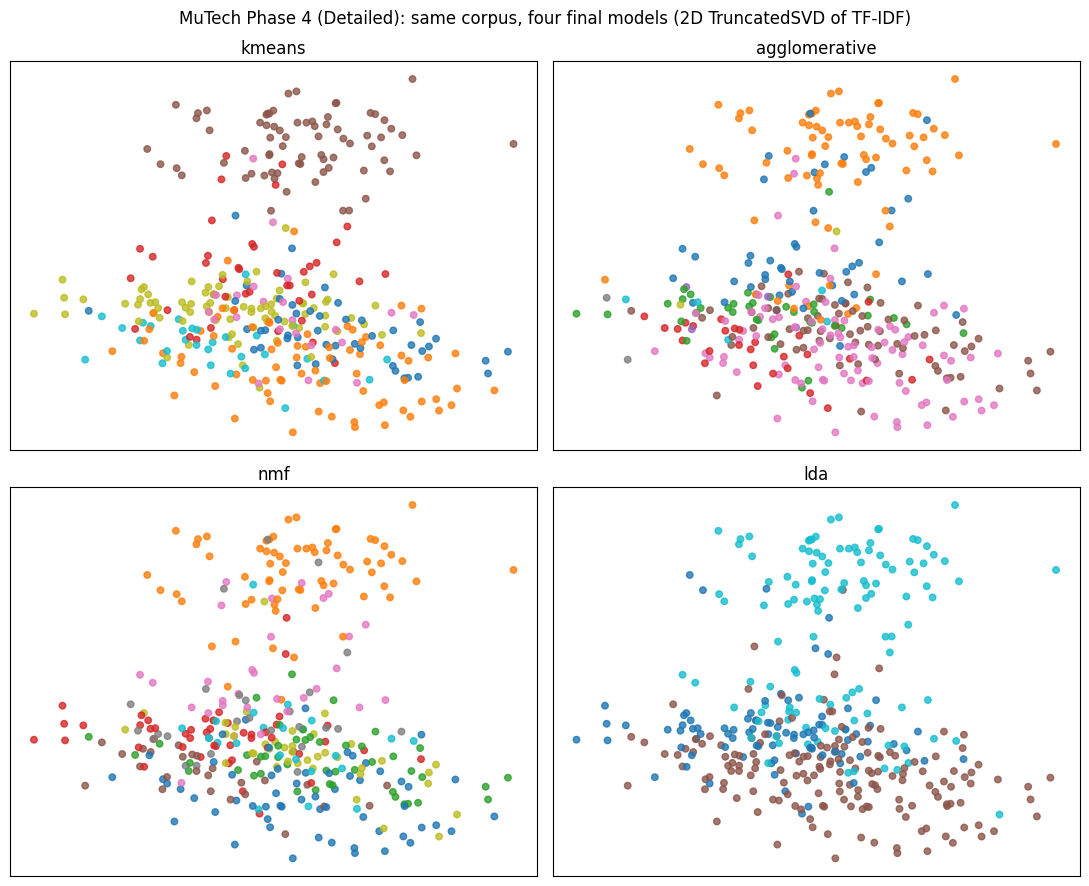

In [60]:
xy_full = TruncatedSVD(n_components=2, random_state=RANDOM_STATE).fit_transform(X_full)
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, (name, labels) in zip(axes.ravel(), final_labels.items()):
    ax.scatter(xy_full[:, 0], xy_full[:, 1], c=labels, cmap="tab10", s=22, alpha=0.8)
    ax.set_title(name)
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("MuTech Phase 4 (Detailed): same corpus, four final models (2D TruncatedSVD of TF-IDF)")
fig.tight_layout()
fig.savefig(os.path.join(OUTDIR, "comparison", "models_2d_final.png"), dpi=150)
plt.show()

### Synthesis table and outputs

In [61]:
synthesis = comparison_df.merge(
    pd.DataFrame([
        {"model": "kmeans", "final_k": KM_FINAL_PARAMS["n_clusters"]},
        {"model": "agglomerative", "final_k": AGG_FINAL_PARAMS["n_clusters"]},
        {"model": "nmf", "final_k": NMF_FINAL_PARAMS["n_components"]},
        {"model": "lda", "final_k": LDA_FINAL_PARAMS["n_components"]},
    ]), on="model")
synthesis.to_csv(os.path.join(OUTDIR, "comparison", "model_comparison_final.csv"), index=False)
secondary_metrics.to_csv(os.path.join(OUTDIR, "comparison", "secondary_metrics_final.csv"), index=False)
synthesis

,model,silhouette_cosine,ari_vs_kmeans,ari_vs_agglomerative,ari_vs_nmf,ari_vs_lda,final_k
0,kmeans,0.0389,1.0000,0.4180,0.5238,0.2837,7
1,agglomerative,0.0279,0.4180,1.0000,0.4629,0.2117,11
2,nmf,0.0385,0.5238,0.4629,1.0000,0.2280,9
3,lda,0.0220,0.2837,0.2117,0.2280,1.0000,3


### Cluster balance
Silhouette won't catch a model that "wins" by dumping most documents into a couple of big
clusters and scattering the rest into tiny 2-3-paper bins. A 2-paper topic isn't a theme,
it's noise, so worth checking cluster size balance directly before trusting the silhouette
numbers alone.

In [62]:
def cluster_balance_stats(labels):
    sizes = pd.Series(labels).value_counts()
    return {
        "n_clusters": len(sizes),
        "min_size": int(sizes.min()),
        "max_size": int(sizes.max()),
        "n_tiny_clusters_lt10": int((sizes < 10).sum()),
        "size_cv": round(float(sizes.std() / sizes.mean()), 3),
    }

balance_rows = []
for name, labels in final_labels.items():
    stats = cluster_balance_stats(labels)
    stats["model"] = name
    balance_rows.append(stats)
balance_df = pd.DataFrame(balance_rows)[
    ["model", "n_clusters", "min_size", "max_size", "n_tiny_clusters_lt10", "size_cv"]]
print(balance_df)

           model  n_clusters  min_size  max_size  n_tiny_clusters_lt10  \
0         kmeans           7        22        79                     0   
1  agglomerative          11         2        87                     5   
2            nmf           9        22        68                     0   
3            lda           3        86       162                     0   

   size_cv  
0    0.439  
1    1.008  
2    0.385  
3    0.314  


### Final model selection

K-Means (0.0389 silhouette) and NMF (0.0385) are basically tied - a 0.0004 gap is noise.
Agglomerative comes in lowest of the non-LDA models at 0.0279, and 5 of its 11 clusters
have 2-5 papers each, which is not a theme, it's an outlier bin. LDA is lowest overall at
0.0220 and only found 3 topics for this corpus, each a merge of subthemes the other three
models keep separate - matches what the quick-pipeline README already flagged about LDA
wanting more documents than this corpus has, and its own train/test perplexity gap here
(895.7 vs 3052.9, by far the widest of any model) backs that up.

So it comes down to K-Means vs NMF, and reading the actual top-terms tables settles it.
All 7 K-Means clusters are genuine, nameable MIR subthemes: instrument recognition, AMT,
singing/melody extraction, source separation, pitch estimation, education/assessment, OMR.
NMF's 9 topics are mostly clean too, but 2 of them are really just "data augmentation /
domain adaptation" and "generic CNN architecture" - methodology, not subject matter. That's
the tiebreak. **Going with K-Means.** If anyone on the team reads the top-terms tables
differently, `nmf_final_assignments.csv` is right there as the alternative.

In [63]:
FINAL_MODEL = "kmeans"
final_selection_summary = (
    "MuTech Phase 4 - FINAL MODEL SELECTION\n"
    f"  selected model : {FINAL_MODEL}\n"
    f"  k              : {KM_FINAL_PARAMS['n_clusters']}\n"
    f"  silhouette     : {safe_silhouette(X_full, km_final_labels):.4f}\n"
    "  runner-up      : nmf (silhouette "
    f"{safe_silhouette(X_full, nmf_final_labels):.4f}, statistically tied, but 2/9 topics "
    "are methodology clusters rather than MIR subthemes)\n"
    "  rejected       : agglomerative (5/11 clusters have <10 papers, lowest silhouette "
    "of the non-LDA models), lda (only 3 topics, under-resolves the corpus, largest "
    "train/test perplexity gap of any model)\n"
)
with open(os.path.join(OUTDIR, "comparison", "FINAL_MODEL_SELECTION.txt"), "w", encoding="utf-8") as f:
    f.write(final_selection_summary)

km_final_assignments.to_csv(
    os.path.join(OUTDIR, "comparison", "FINAL_SELECTED_assignments.csv"), index=False)
km_final_top_terms.to_csv(
    os.path.join(OUTDIR, "comparison", "FINAL_SELECTED_top_terms.csv"), index=False)

print(final_selection_summary)
print("Saved FINAL_MODEL_SELECTION.txt, FINAL_SELECTED_assignments.csv, "
      "FINAL_SELECTED_top_terms.csv to comparison/")

MuTech Phase 4 - FINAL MODEL SELECTION
  selected model : kmeans
  k              : 7
  silhouette     : 0.0389
  runner-up      : nmf (silhouette 0.0385, statistically tied, but 2/9 topics are methodology clusters rather than MIR subthemes)
  rejected       : agglomerative (5/11 clusters have <10 papers, lowest silhouette of the non-LDA models), lda (only 3 topics, under-resolves the corpus, largest train/test perplexity gap of any model)

Saved FINAL_MODEL_SELECTION.txt, FINAL_SELECTED_assignments.csv, FINAL_SELECTED_top_terms.csv to comparison/


In [64]:
run_summary_lines = [
    "MuTech Phase 4 (Detailed) - run summary",
    f"  papers (full corpus)     : {len(corpus)}",
    f"  train / test split       : {len(tok_train)} / {len(tok_test)} (80/20, random_state={RANDOM_STATE})",
    f"  baseline k (train-only)  : {BASELINE_K}",
    "",
    "Final full-corpus models:",
    f"  kmeans        : k={KM_FINAL_PARAMS['n_clusters']}, silhouette={safe_silhouette(X_full, km_final_labels):.4f}",
    f"  agglomerative : n_clusters={AGG_FINAL_PARAMS['n_clusters']}, linkage={AGG_FINAL_PARAMS['linkage']}, "
    f"silhouette={safe_silhouette(X_full, agg_final_labels):.4f}",
    f"  nmf           : n_components={NMF_FINAL_PARAMS['n_components']}, "
    f"silhouette={safe_silhouette(X_full, nmf_final_labels):.4f}, "
    f"reconstruction_err_={nmf_final.reconstruction_err_:.3f}",
    f"  lda           : n_components={LDA_FINAL_PARAMS['n_components']}, perplexity={lda_final_perp:.1f}, "
    f"umass_coherence={lda_coherence_overall:.4f}",
    "",
    "Comparison:",
    comparison_df.to_string(index=False),
    "",
    f"FINAL MODEL SELECTED: {FINAL_MODEL} (see comparison/FINAL_MODEL_SELECTION.txt for rationale)",
]
run_summary = "\n".join(run_summary_lines)
with open(os.path.join(OUTDIR, "comparison", "notebook_run_summary.txt"), "w", encoding="utf-8") as f:
    f.write(run_summary)
print(run_summary)

MuTech Phase 4 (Detailed) - run summary
  papers (full corpus)     : 365
  train / test split       : 292 / 73 (80/20, random_state=42)
  baseline k (train-only)  : 7

Final full-corpus models:
  kmeans        : k=7, silhouette=0.0389
  agglomerative : n_clusters=11, linkage=average, silhouette=0.0279
  nmf           : n_components=9, silhouette=0.0385, reconstruction_err_=17.646
  lda           : n_components=3, perplexity=967.8, umass_coherence=-0.8492

Comparison:
        model  silhouette_cosine  ari_vs_kmeans  ari_vs_agglomerative  ari_vs_nmf  ari_vs_lda
       kmeans             0.0389         1.0000                0.4180      0.5238      0.2837
agglomerative             0.0279         0.4180                1.0000      0.4629      0.2117
          nmf             0.0385         0.5238                0.4629      1.0000      0.2280
          lda             0.0220         0.2837                0.2117      0.2280      1.0000

FINAL MODEL SELECTED: kmeans (see comparison/FINAL_MODEL_